<a href="https://colab.research.google.com/github/pedrozinn2102/DataScience/blob/main/Trabalho_Data_Science_14_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Laboratório: Ciência de Dados aplicada ao Marketing Digital**

**Grupo:** Leonardo Lariú e Pedro Zinn.

##Etapa 1 — Contextualização

**Perguntas de negócio**

1. Qual canal gera mais conversões com menor custo e maior retorno?

O Google Ads se destacou, com 416 conversões, CPA de R$ 19,83 e ROAS de 7,56. Entre os canais analisados, ele apresentou a melhor combinação desses indicadores, sendo uma boa opção para testar um aumento controlado no orçamento.

2. O aumento do investimento acompanha o crescimento das conversões e do retorno?

Os dados indicam que o investimento e as conversões tendem a crescer juntos, mas o retorno não acompanha esse movimento em todos os canais. No Meta Ads e no LinkedIn Ads, por exemplo, o ROAS caiu nas últimas semanas. Isso mostra que investir mais não garante, por si só, um retorno proporcionalmente maior.

**Decisões possíveis**

- Testar um aumento de orçamento no canal com melhor desempenho.
- Revisar campanhas que apresentam sinais de perda de eficiência.

**Hipótese inicial**

Acreditamos que a campanha Pesquisa Marca, do Google Ads, possa apresentar melhores resultados por alcançar pessoas que já conhecem a empresa ou estão mais próximas de uma decisão de compra. Essa hipótese será comparada com os dados, mas não pode ser confirmada apenas com a base disponível.


## Etapa 2 — Conhecendo e tratando os dados

### 2.1 Importar a biblioteca e ler o CSV

In [2]:
import pandas as pd
df = pd.read_csv('campanhas_marketing_digital.csv', sep=',', header=0, encoding='utf-8-sig')
df.head(4)

,data,canal,campanha,etapa_funil,investimento,impressoes,alcance,cliques,interacoes,leads,conversoes,receita
0,2026-08-03,Google Ads,Pesquisa Marca,Fundo de funil,1200,52000,41000,2600,310,150.0,58,8700
1,2026-08-03,Meta Ads,Conversao Social,Meio de funil,1000,78000,59000,2340,410,118.0,42,5200
2,2026-08-03,Instagram,Conteudo Impulsionado,Topo de funil,650,92000,68000,1840,520,72.0,18,1800
3,2026-08-03,LinkedIn Ads,Leads B2B,Meio de funil,900,31000,24500,930,145,64.0,16,4800


### 2.2 Estrutura, tipos e variáveis — Exercício 1a e 1b

In [3]:
df.tail(4)

,data,canal,campanha,etapa_funil,investimento,impressoes,alcance,cliques,interacoes,leads,conversoes,receita
20,2026-09-07,Google Ads,Pesquisa Marca,Fundo de funil,1600,65000,50000,3640,420,205.0,80,12000
21,2026-09-07,Meta Ads,Conversao Social,Meio de funil,1450,96000,72000,2688,510,151.0,55,6875
22,2026-09-07,Instagram,Conteudo Impulsionado,Topo de funil,1000,116000,83000,2088,660,90.0,24,2400
23,2026-09-07,LinkedIn Ads,Leads B2B,Meio de funil,1350,40000,31000,1080,184,84.0,21,6300


In [4]:
print('Registros: %d' % df.shape[0])
print('Variáveis: %d' % df.shape[1])
df.info()

Registros: 24
Variáveis: 12
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24 entries, 0 to 23
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   data          24 non-null     object 
 1   canal         24 non-null     object 
 2   campanha      24 non-null     object 
 3   etapa_funil   24 non-null     object 
 4   investimento  24 non-null     int64  
 5   impressoes    24 non-null     int64  
 6   alcance       24 non-null     int64  
 7   cliques       24 non-null     int64  
 8   interacoes    24 non-null     int64  
 9   leads         23 non-null     float64
 10  conversoes    24 non-null     int64  
 11  receita       24 non-null     int64  
dtypes: float64(1), int64(7), object(4)
memory usage: 2.4+ KB


In [5]:
df.columns

Index(['data', 'canal', 'campanha', 'etapa_funil', 'investimento',
       'impressoes', 'alcance', 'cliques', 'interacoes', 'leads', 'conversoes',
       'receita'],
      dtype='object')

In [6]:
df['investimento'].describe()

,investimento
count,24.000000
mean,1111.666667
std,255.864547
min,650.000000
25%,937.500000
50%,1100.000000
75%,1300.000000
max,1600.000000


**Exercício 1a:** a entrada tem 24 registros e 12 variáveis: quatro canais durante seis semanas, de 03/08/2026 a 07/09/2026. Cada linha é um canal em uma semana.

**Exercício 1b — classificação:**

| Variável | Classificação | Tipo observado / tratamento |
|---|---|---|
| `canal` | Categórica nominal | Texto na leitura |
| `investimento` | Numérica monetária | Inteiro na leitura desta base; representa dinheiro |
| `data` | Temporal | Texto na leitura; converter para data/hora |
| `conversoes` | Numérica discreta | Contagem inteira |

### 2.3 Localizar e corrigir os problemas — Exercício 1c e 1d

In [7]:
df[df['leads'].isna()]

,data,canal,campanha,etapa_funil,investimento,impressoes,alcance,cliques,interacoes,leads,conversoes,receita
14,2026-08-24,Instagram,Conteudo Impulsionado,Topo de funil,820,105000,76000,2100,602,NaN,22,2200


In [8]:
df.query('canal == "Instagram "')

,data,canal,campanha,etapa_funil,investimento,impressoes,alcance,cliques,interacoes,leads,conversoes,receita
6,2026-08-10,Instagram,Conteudo Impulsionado,Topo de funil,700,96000,70400,2016,548,78.0,20,2000


In [9]:
print('Linhas duplicadas: %d' % df.duplicated().sum())

Linhas duplicadas: 0


**Exercício 1c — problemas localizados:**
- Instagram em 24/08/2026, posição 14, tem `leads` ausente.
- Instagram em 10/08/2026, posição 6, está escrito como `'Instagram '` com espaço no final.
- **Tipo:** `data` foi lida como texto.

#### Tratamento dos dados

Removemos os espaços extras de `canal` e convertemos `data` para data/hora. **O lead ausente continua `NaN`.**

In [10]:
df['canal'] = df['canal'].str.strip()
df['data'] = pd.to_datetime(df['data'], format='%Y-%m-%d')
df.dtypes

,0
data,datetime64[ns]
canal,object
campanha,object
etapa_funil,object
investimento,int64
impressoes,int64
alcance,int64
cliques,int64
interacoes,int64
leads,float64


In [11]:
df.query('canal == "Instagram "')

,data,canal,campanha,etapa_funil,investimento,impressoes,alcance,cliques,interacoes,leads,conversoes,receita


In [12]:
print('Leads preenchidos: %d' % df['leads'].count())
print('Leads ausentes: %d' % (df.shape[0] - df['leads'].count()))
df[df['leads'].isna()]

Leads preenchidos: 23
Leads ausentes: 1


,data,canal,campanha,etapa_funil,investimento,impressoes,alcance,cliques,interacoes,leads,conversoes,receita
14,2026-08-24,Instagram,Conteudo Impulsionado,Topo de funil,820,105000,76000,2100,602,NaN,22,2200


**Exercício 1d:** o Instagram em 24/08/2026 está sem o número de leads. Isso não significa zero, e sim que o valor não foi registrado. Colocar zero diria que a campanha não gerou nenhum lead, o que faria o Instagram parecer pior e deixaria somas e médias erradas. Por isso, mantivemos o campo vazio e registramos isso nas limitações. Como as cinco métricas não usam leads, os resultados não mudam.

**Respostas da Etapa 2:**
1. **Informações disponíveis:** data, canal, campanha, etapa do funil, investimento, impressões, alcance, cliques, interações, leads, conversões e receita. A base não especifica que toda conversão seja venda nem detalha os tipos de interação.
2. **Variáveis essenciais:** investimento, impressões, cliques, conversões e receita para as cinco métricas; canal e data para comparação e evolução; etapa do funil para interpretar o objetivo. Leads, alcance e interações dão contexto adicional.
3. **Qualidade:** um lead ausente, um espaço extra em `canal`, datas inicialmente textuais e nenhuma duplicata.
4. **Perguntas respondíveis:** qual canal mais converte, qual tem melhor taxa, menor CPC/CPA e maior ROAS; como os resultados evoluem e se investimento e conversões estão associados. A base não permite calcular lucro nem isolar efeito causal.

## Etapa 3 — Análise exploratória

### 3.1 Cinco métricas por registro

| Métrica | Fórmula do roteiro | Pergunta |
|---|---|---|
| CTR | cliques / impressões × 100 | O anúncio gera interesse inicial? |
| Taxa de conversão | conversões / cliques × 100 | O tráfego realiza a ação esperada? |
| CPC | investimento / cliques | Quanto custa gerar um clique? |
| CPA | investimento / conversões | Quanto custa cada conversão? |
| ROAS | receita / investimento | Quanto de receita por real investido em mídia? |

CTR e conversão são porcentagens; CPC e CPA são dinheiro; ROAS é razão. ROAS não é lucro nem ROI: faltam custos operacionais, margem, impostos e atribuição multicanal. Nesta base os denominadores usados são positivos.

In [13]:
df.insert(12, 'ctr', df['cliques'] / df['impressoes'] * 100)
df.insert(13, 'taxa_conversao', df['conversoes'] / df['cliques'] * 100)
df.insert(14, 'cpc', df['investimento'] / df['cliques'])
df.insert(15, 'cpa', df['investimento'] / df['conversoes'])
df.insert(16, 'roas', df['receita'] / df['investimento'])
df[['data', 'canal', 'ctr', 'taxa_conversao', 'cpc', 'cpa', 'roas']].head(8)

,data,canal,ctr,taxa_conversao,cpc,cpa,roas
0,2026-08-03,Google Ads,5.0,2.230769,0.461538,20.689655,7.250000
1,2026-08-03,Meta Ads,3.0,1.794872,0.427350,23.809524,5.200000
2,2026-08-03,Instagram,2.0,0.978261,0.353261,36.111111,2.769231
3,2026-08-03,LinkedIn Ads,3.0,1.720430,0.967742,56.250000,5.333333
4,2026-08-10,Google Ads,5.3,2.201258,0.436758,19.841270,7.560000
5,2026-08-10,Meta Ads,3.1,1.831939,0.418160,22.826087,5.476190
6,2026-08-10,Instagram,2.1,0.992063,0.347222,35.000000,2.857143
7,2026-08-10,LinkedIn Ads,3.0,1.743590,0.974359,55.882353,5.368421


### Exercício 2 — Google Ads em 03/08/2026, com duas casas decimais

In [14]:
dia = pd.to_datetime('2026-08-03', format='%Y-%m-%d')
linha = df.query('canal == "Google Ads" and data == @dia')
registro = linha.iloc[0]
print('CTR: %.2f%%' % registro['ctr'])
print('Taxa de conversão: %.2f%%' % registro['taxa_conversao'])
print('CPC: R$ %.2f' % registro['cpc'])
print('CPA: R$ %.2f' % registro['cpa'])
print('ROAS: %.2f' % registro['roas'])

CTR: 5.00%
Taxa de conversão: 2.23%
CPC: R$ 0.46
CPA: R$ 20.69
ROAS: 7.25


**Conferência das contas:** investimento R\$ 1.200; 52.000 impressões; 2.600 cliques; 58 conversões; receita R\$ 8.700.

| Métrica | Conta | Resultado |
|---|---|---|
| CTR | 2.600 / 52.000 × 100 | 5,00% |
| Conversão | 58 / 2.600 × 100 | 2,23% |
| CPC | 1.200 / 2.600 | R\$ 0,46 |
| CPA | 1.200 / 58 | R\$ 20,69 |
| ROAS | 8.700 / 1.200 | 7,25 |

### 3.2 Tabela por canal — Exercício 3

As métricas agregadas são calculadas pela **razão entre somas**, e não pela média simples das taxas semanais. O arredondamento é somente para exibição; os cálculos mantêm a precisão original.

In [15]:
por_canal = df.groupby('canal', as_index=False)[['investimento', 'impressoes', 'cliques', 'conversoes', 'receita']].sum()
por_canal.insert(6, 'ctr', por_canal['cliques'] / por_canal['impressoes'] * 100)
por_canal.insert(7, 'taxa_conversao', por_canal['conversoes'] / por_canal['cliques'] * 100)
por_canal.insert(8, 'cpc', por_canal['investimento'] / por_canal['cliques'])
por_canal.insert(9, 'cpa', por_canal['investimento'] / por_canal['conversoes'])
por_canal.insert(10, 'roas', por_canal['receita'] / por_canal['investimento'])
por_canal.round(2)

,canal,investimento,impressoes,cliques,conversoes,receita,ctr,taxa_conversao,cpc,cpa,roas
0,Google Ads,8250,348000,18902,416,62400,5.43,2.20,0.44,19.83,7.56
1,Instagram,4830,620000,12154,128,12800,1.96,1.05,0.40,37.73,2.65
2,LinkedIn Ads,6500,211500,6113,111,33300,2.89,1.82,1.06,58.56,5.12
3,Meta Ads,7100,519000,15451,296,36950,2.98,1.92,0.46,23.99,5.20


**Objetivo no funil:** nesta base, Google está no fundo; Meta e LinkedIn, no meio; Instagram, no topo. Há uma campanha e uma etapa por canal.

In [16]:
funil = pd.DataFrame([
    ['Google Ads', 'Fundo de funil'],
    ['Meta Ads', 'Meio de funil'],
    ['Instagram', 'Topo de funil'],
    ['LinkedIn Ads', 'Meio de funil']
], columns=['canal', 'etapa_funil'])
por_canal = pd.merge(left=por_canal, right=funil, on='canal')
por_canal.round(2)

,canal,investimento,impressoes,cliques,conversoes,receita,ctr,taxa_conversao,cpc,cpa,roas,etapa_funil
0,Google Ads,8250,348000,18902,416,62400,5.43,2.20,0.44,19.83,7.56,Fundo de funil
1,Instagram,4830,620000,12154,128,12800,1.96,1.05,0.40,37.73,2.65,Topo de funil
2,LinkedIn Ads,6500,211500,6113,111,33300,2.89,1.82,1.06,58.56,5.12,Meio de funil
3,Meta Ads,7100,519000,15451,296,36950,2.98,1.92,0.46,23.99,5.20,Meio de funil


In [17]:
por_canal.to_csv('tabela_por_canal.csv')

### 3.3 Ordenar por volume, taxa, custo e retorno

In [18]:
por_canal.sort_values(by='conversoes', ascending=False)[['canal', 'conversoes']]

,canal,conversoes
0,Google Ads,416
3,Meta Ads,296
1,Instagram,128
2,LinkedIn Ads,111


In [19]:
por_canal.sort_values(by='taxa_conversao', ascending=False)[['canal', 'taxa_conversao']]

,canal,taxa_conversao
0,Google Ads,2.200825
3,Meta Ads,1.915734
2,LinkedIn Ads,1.815802
1,Instagram,1.053151


In [20]:
por_canal.sort_values(by='cpa')[['canal', 'cpa']]

,canal,cpa
0,Google Ads,19.831731
3,Meta Ads,23.986486
1,Instagram,37.734375
2,LinkedIn Ads,58.558559


In [21]:
por_canal.sort_values(by='roas', ascending=False)[['canal', 'roas']]

,canal,roas
0,Google Ads,7.563636
3,Meta Ads,5.204225
2,LinkedIn Ads,5.123077
1,Instagram,2.650104


**Respostas do Exercício 3:**
1. **Maior volume:** Google Ads, 416 conversões.
2. **Maior taxa de conversão:** Google Ads, 2,20%.
3. **Maior ROAS:** Google Ads, 7,56.
4. **Menor CPA:** Google Ads, R\$ 19,83.
5. **Investimento relevante e retorno relativo menor:** LinkedIn Ads investiu R\$ 6.500, teve 111 conversões, CPA de R\$ 58,56 e ROAS de 5,12, abaixo do Google. Meta também merece comparação: R\$ 7.100 e ROAS de 5,20. “Alto” e “baixo” são comparações internas à base, sem um limite universal informado. Instagram tem o menor ROAS (2,65), mas também o menor investimento (R\$ 4.830) e objetivo de topo de funil.

**Volume e eficiência:** Meta tem o segundo maior volume (296 conversões), mas ROAS 5,20, próximo ao LinkedIn (5,12). Mais conversões não implica eficiência superior em toda métrica. Google lidera conversões, taxa, CPA e ROAS, porém Instagram tem o menor CPC: R\$ 0,40. Portanto, Google não é o melhor em todas as métricas.

Os diferentes objetivos do funil ajudam a contextualizar resultados diretos, mas não provam contribuições entre canais. Conversão não significa necessariamente venda, e a base não permite afirmar lucro ou valor de venda por cliente.

## Etapa 4 — Visualizações

### Gráfico 1 — Conversões por canal (barras)

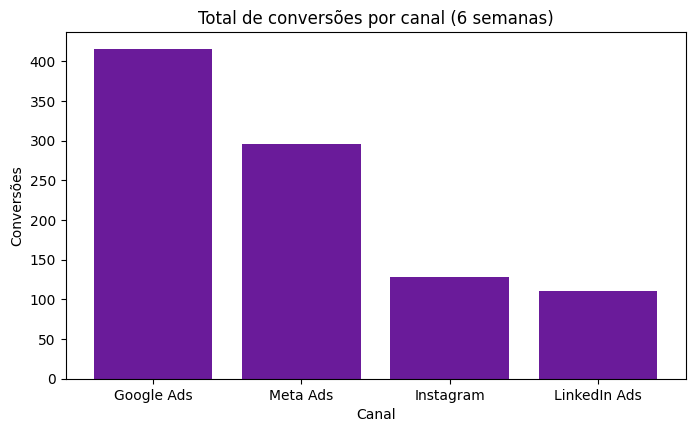

In [22]:
import matplotlib.pyplot as plt
ordenado = por_canal.sort_values(by='conversoes', ascending=False)
plt.figure(figsize=(8, 4.5))
plt.bar(ordenado['canal'], ordenado['conversoes'], color='#6a1b9a')
plt.title('Total de conversões por canal (6 semanas)')
plt.xlabel('Canal')
plt.ylabel('Conversões')
plt.show()

- **Padrão:** Google Ads lidera com 416 conversões, seguido de Meta (296), Instagram (128) e LinkedIn (111). Google representa aproximadamente 44% das 951 conversões.
- **Relevância:** mostra onde está o maior volume de resultados e dá uma primeira evidência para investigar orçamento.
- **Ressalva:** volume não basta; é preciso considerar CPA, ROAS e objetivo no funil. Uma campanha e uma etapa por canal impedem separar completamente esses efeitos.

### Gráfico 2 — Conversões ao longo do tempo, por canal (linha)

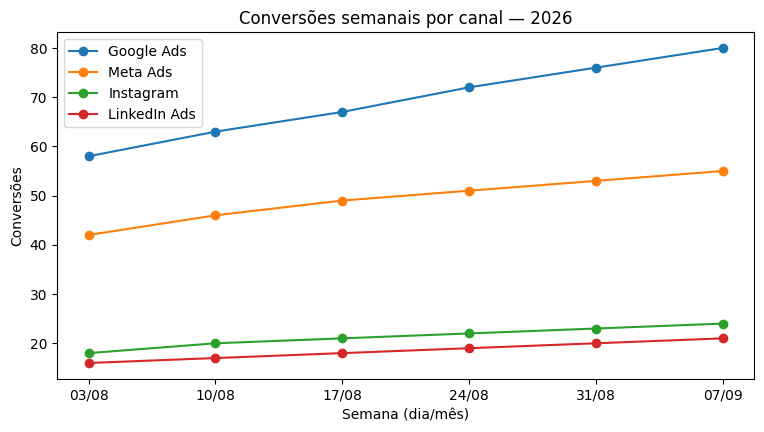

In [23]:
canais = ['Google Ads', 'Meta Ads', 'Instagram', 'LinkedIn Ads']
plt.figure(figsize=(9, 4.5))
for canal in canais:
    dados = df.query('canal == @canal')
    dados = dados.sort_values(by='data')
    plt.plot(dados['data'].dt.strftime('%d/%m'), dados['conversoes'], marker='o', label=canal)
plt.title('Conversões semanais por canal — 2026')
plt.xlabel('Semana (dia/mês)')
plt.ylabel('Conversões')
plt.legend()
plt.show()

### Exercício 4a — conferir conversões e investimento semana a semana

In [24]:
for canal in canais:
    dados = df.query('canal == @canal')
    dados = dados.sort_values(by='data')
    print('Canal: %s' % canal)
    print('Conversões: %s' % list(dados['conversoes']))
    print('Investimento: %s' % list(dados['investimento']))

Canal: Google Ads
Conversões: [58, 63, 67, 72, 76, 80]
Investimento: [1200, 1250, 1300, 1400, 1500, 1600]
Canal: Meta Ads
Conversões: [42, 46, 49, 51, 53, 55]
Investimento: [1000, 1050, 1100, 1200, 1300, 1450]
Canal: Instagram
Conversões: [18, 20, 21, 22, 23, 24]
Investimento: [650, 700, 760, 820, 900, 1000]
Canal: LinkedIn Ads
Conversões: [16, 17, 18, 19, 20, 21]
Investimento: [900, 950, 1000, 1100, 1200, 1350]


- **Padrão / Exercício 4a:** sim, as conversões crescem em todos os canais nas seis semanas: Google 58-80; Meta 42-55; Instagram 18-24; LinkedIn 16-21. As listas mostram os valores intermediários.
- **Relevância:** permite acompanhar a evolução, em vez de olhar somente os totais do período.
- **Ressalva:** o investimento também cresce semanalmente em todos os canais. Tempo, dinheiro e possíveis fatores não medidos variam juntos; seis semanas não isolam o efeito de cada um.

### Gráfico 3 — Investimento × conversões, com canal identificado (dispersão)

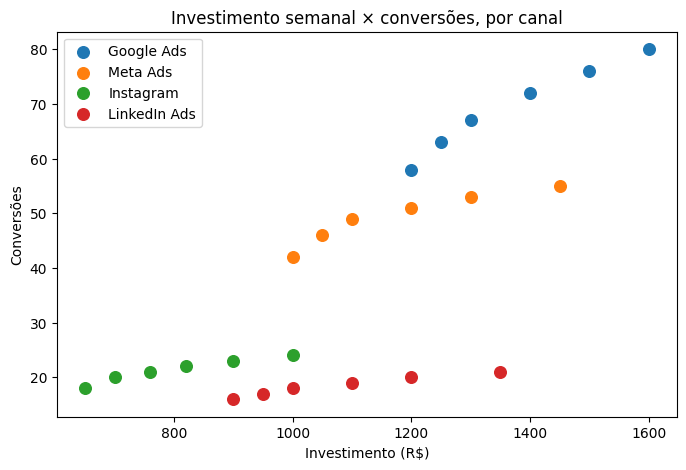

In [25]:
plt.figure(figsize=(8, 5))
for canal in canais:
    dados = df.query('canal == @canal')
    plt.scatter(dados['investimento'], dados['conversoes'], s=70, label=canal)
plt.title('Investimento semanal × conversões, por canal')
plt.xlabel('Investimento (R$)')
plt.ylabel('Conversões')
plt.legend()
plt.show()

### Exercício 4b — Correlação entre investimento e conversões

A correlação de Pearson mede associação linear. Calculamos o coeficiente para as 24 observações e para cada canal.

In [26]:
print('Correlação geral: %.2f' % df['investimento'].corr(df['conversoes']))
for canal in canais:
    dados = df.query('canal == @canal')
    print('%s: %.2f' % (canal, dados['investimento'].corr(dados['conversoes'])))

Correlação geral: 0.79
Google Ads: 0.98
Meta Ads: 0.94
Instagram: 0.97
LinkedIn Ads: 0.98


- **Padrão:** há associação positiva; a correlação geral é aproximadamente 0,79. Por canal: Google 0,98, Meta 0,94, Instagram 0,97 e LinkedIn 0,98. Os canais formam grupos distintos na dispersão. Com R\$ 1.200, por exemplo, Google tem 58 conversões em 03/08 e LinkedIn 20 em 31/08; são datas diferentes, não uma comparação controlada.
- **Relevância:** investigar associação ajuda a discutir escala e custo de conversão, considerando a estratégia de cada canal.
- **Ressalva / Exercício 4c:** **correlação não prova causalidade**. Investimento e conversões aumentam junto com o tempo. Público, criativo, sazonalidade e jornada não foram isolados. As correlações por canal usam apenas seis observações cada. Seria necessário um experimento com controle para investigar o efeito do orçamento.

### Retorno semanal

A tabela mostra investimento, conversões e ROAS por data.

In [27]:
df[['data', 'canal', 'investimento', 'conversoes', 'roas']].round(2)

,data,canal,investimento,conversoes,roas
0,2026-08-03,Google Ads,1200,58,7.25
1,2026-08-03,Meta Ads,1000,42,5.20
2,2026-08-03,Instagram,650,18,2.77
3,2026-08-03,LinkedIn Ads,900,16,5.33
4,2026-08-10,Google Ads,1250,63,7.56
5,2026-08-10,Meta Ads,1050,46,5.48
6,2026-08-10,Instagram,700,20,2.86
7,2026-08-10,LinkedIn Ads,950,17,5.37
8,2026-08-17,Google Ads,1300,67,7.73
9,2026-08-17,Meta Ads,1100,49,5.57


**Leitura:** de **17/08 a 07/09**, nas três transições finais, ROAS do Meta cai de **5,57 para 4,74** e do LinkedIn de **5,40 para 4,67**, enquanto investimento e conversões sobem. Mais conversões não garantem maior retorno por real. Isso merece investigação; não demonstra que a mudança do orçamento causou a queda.

## Etapa 5 — Insights e recomendações — Exercício 5

### Insight 1 — O Google Ads apresenta os melhores resultados gerais

O Google Ads registrou 416 conversões, CPA de R$ 19,83 e ROAS de 7,56, destacando-se entre os canais analisados.

**Recomendação:** testar um aumento controlado no orçamento, comparando os resultados com um grupo de controle para verificar se o investimento adicional realmente compensa.

### Insight 2 — Meta Ads e LinkedIn Ads precisam de atenção

Nas últimas semanas, o ROAS do Meta Ads caiu de 5,57 para 4,74, enquanto o do LinkedIn Ads caiu de 5,40 para 4,67. Isso indica uma redução no retorno em relação ao investimento.

**Recomendação:** revisar os anúncios e os públicos desses canais, testando mudanças individualmente antes de ampliar o orçamento.

### Insight 3 — Cliques baratos não garantem mais conversões

O Instagram apresentou o menor custo por clique, de R$ 0,40, mas teve taxa de conversão de 1,05% e ROAS de 2,65.

**Recomendação:** investigar o que acontece depois do clique e testar melhorias nos anúncios ou nas páginas de destino. Também vale considerar que o canal pode contribuir para despertar o interesse de pessoas que ainda não estão prontas para comprar.

### Hipótese complementar

Uma possível explicação para as diferenças é que o Google Ads alcance pessoas mais próximas da compra, enquanto o Instagram ajude a apresentar a marca a novos públicos. No entanto, os dados não permitem confirmar essa hipótese nem medir toda a contribuição de cada canal.


## Conclusão

A análise mostrou diferenças importantes no desempenho dos quatro canais de mídia. O Google Ads se destacou, com 416 conversões, CPA de R\$ 19,83 e ROAS de 7,56, sendo o canal com a melhor combinação de volume, custo e retorno. Já o LinkedIn Ads apresentou o maior custo por conversão, de R\$ 58,56, e o Instagram, apesar do menor custo por clique, teve a menor taxa de conversão, de 1,05%. Também observamos que o ROAS de Meta Ads e LinkedIn Ads caiu nas últimas semanas, mesmo com o aumento do investimento.

Os resultados ajudam a identificar oportunidades de melhoria, mas não são suficientes para determinar o lucro real ou comprovar relações de causa e efeito.

Por isso, o próximo passo é testar as recomendações na prática, acompanhando não apenas as conversões, mas também o custo, o retorno e a margem.


## Limitações

- **Base reduzida:** são 24 registros distribuídos por seis semanas.
- **Ausência de dados financeiros completos:** não temos todos os custos necessários para calcular o lucro real.
- **Atribuição desconhecida:** não sabemos como o crédito pelas conversões foi distribuído entre os canais.
- **Informações incompletas:** um registro do Instagram não possui o dado de leads.
- **Poucos detalhes das campanhas:** faltam informações sobre públicos, criativos, dispositivos e etapas da jornada.
- **Limite de interpretação:** a relação entre investimento e conversões não comprova que um tenha causado o outro.

## Etapa 6 — Apresentação de até dois minutos

Analisamos uma base fictícia com quatro canais de mídia ao longo de seis semanas.

O principal destaque foi o Google Ads, que apresentou o maior número de conversões e os melhores resultados de CPA e ROAS. Já o Instagram teve o menor custo por clique, mas isso não se refletiu na mesma proporção em conversões diretas.

Também observamos uma queda recente no ROAS de Meta Ads e LinkedIn Ads, o que indica a necessidade de investigar o desempenho dessas campanhas.

Nossa recomendação é testar um aumento controlado no orçamento do Google Ads e revisar as campanhas de Meta e LinkedIn antes de investir mais. No Instagram, vale entender melhor o comportamento do público após o clique.

É importante lembrar que os dados não mostram o lucro real nem comprovam que o investimento causou o crescimento das conversões. Por isso, precisamos testar as mudanças e acompanhar os resultados antes de tomar decisões definitivas.


## Questões orientadoras — respostas

**1. Qual canal teve mais conversões?**

Google Ads, com 416 conversões.

**2. Qual teve a maior taxa de conversão?**

Google Ads, com 2,20%.

**3. Qual campanha apresentou o melhor desempenho em relação ao investimento?**

A campanha Pesquisa Marca, do Google Ads, destacou-se pelo menor CPA e maior ROAS.

**4. Existe canal com alto investimento e baixo retorno?**

Sim. O LinkedIn Ads investiu R\$ 6.500, mas teve o menor número de conversões, 111, e o maior CPA, de R\$ 58,56. O Meta Ads também merece atenção, pois investiu R$ 7.100 e teve queda recente no ROAS.

**5. Existe relação entre investimento e conversões?**

Sim. A correlação geral foi de aproximadamente 0,79, indicando que as duas variáveis tendem a crescer juntas. Isso não comprova causalidade.

**6. Quais campanhas merecem investigação adicional?**

As campanhas de Meta Ads e LinkedIn Ads, pela queda recente no ROAS, e a do Instagram, porque o custo por clique baixo não se refletiu na mesma proporção em conversões.

**7. Que decisão poderia ser tomada?**

Testar um aumento controlado no orçamento do Google Ads e revisar as campanhas de Meta e LinkedIn antes de investir mais.

**8. Que dados ajudariam a aprofundar a análise?**

Margem, LTV, novos clientes, compras recorrentes e informações sobre públicos, criativos e atribuição.


## Discussão e fechamento

**Um canal com maior alcance deve receber mais orçamento?**

Não necessariamente. Precisamos considerar o objetivo da campanha, o custo e a qualidade dos resultados, e não apenas quantas pessoas foram alcançadas.

**Como a etapa do funil influencia a análise?**

Campanhas de reconhecimento e campanhas de conversão têm objetivos diferentes. Por isso, avaliar apenas as conversões diretas pode deixar de fora parte da contribuição de um canal.

**O que perderíamos ao escolher apenas uma métrica?**

A visão do todo. O Instagram, por exemplo, tem o menor custo por clique, mas a menor taxa de conversão. Olhando só para o CPC, ele pareceria o melhor canal, o que não se confirma quando consideramos as conversões e o retorno.

**Como a atribuição pode afetar os resultados?**

O modelo de atribuição determina como o crédito por uma conversão é distribuído. Sem conhecer esse modelo, precisamos ter cuidado ao comparar os canais.

**Que dados adicionais seriam essenciais?**

Margem, novos clientes, compras recorrentes, LTV, dispositivo, público, criativo e modelo de atribuição. Sem essas informações, não conseguimos avaliar o lucro real nem a contribuição de cada canal ao longo da jornada.

**Como testar as recomendações?**

Podemos testar mudanças controladas no orçamento, nos criativos ou nos públicos, mantendo uma referência de comparação e avaliando os resultados antes de ampliar o investimento.

**Quando a correlação pode levar a uma decisão errada?**

Quando interpretamos duas coisas que acontecem juntas como se uma necessariamente causasse a outra. Outros fatores podem explicar parte do resultado.

## Ticket de saída

Antes de recomendar uma mudança de orçamento, eu verificaria a margem, a atribuição e os resultados de testes controlados, porque a decisão deve se basear não apenas nos números apresentados, mas também na capacidade de o investimento gerar resultados que realmente compensem.


# Utilização de IA

Utilizamos o ChatGPT para nos auxiliar nas seguintes questões:
- Criação do código dos três gráficos;
- Criação da tabela em formato de texto no exercício 1b;
- Criação da tabela em formato de texto na etapa 3.1;
- Criação da tabela em formato de texto após o exercício 2;
- Interpretação da tabela em alguns momentos.